### **Student Information**
GitHub ID: JFVR2398

Kaggle name: Juan Francisco Verdugo Rivas (Rose)

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

***

# **Project Report**

---
## 1. Model Development (10 pts Required)

This report explains the process of developing the model for the Kaggle competition from the DM2026-Lab2-Homework. The code was executed in the cloud via Kaggle. The outputs from the code in this notebook where run locally; to achieve this the outputs from the notebook in Kaggle were downloaded and can be found in the folder called "kaggle".
The competition had four datasets:
- final_posts.json: a list with 4,800 dictionaries. Each element had a post_id and the content of the publication.
- data_identification.csv: it had two columns. The first one was post_id and the second one to which set each post belonged (train or test).
- emotion.csv: a table with two columns. The first one was post_id and the second one the emotion label each post received. It only had posts from the training set.
- sampleSubmission.csv: an example of the shape of the file that needs to be submitted.

### 1.1 Preprocessing Steps

The first step was to created the necessary datasets for working with the data. The tables train_df and test_df were created which included the post_id, the content, and the emotion label. The data was different from the dataset used in the master notebook and the agent pipeline notebook because it had six emotions instead of four. The training dataset was a highly unbalanced. For example, in the dataset the label of joy had the bigger frequency (875 posts) and fear had the lowest one (288 posts). The text in the posts were short, half of them had 13 words or less (average was 16.5).

Using the master notebook code, two versions of the posts were saved in the dataset: one with the original text and the second one with the text cleaned. The cleaned version was used for the TF-IDF model and the original text was used with the transformes. For the twitter-RoBERTa-base model additional preprocessing steps were followed using the recommendations from the model card [(link)](https://huggingface.co/cardiffnlp/twitter-roberta-base-2022-154m) which consists on replacing the usernames of the tweets with "@user" and the links as "http".

For testing and validation, the training dataset was divided in two parts. One had 80% of the data and the other one 20%. This was used for validating each model. This partitioning of the data was stratified to maintain the same distribution of emotions and the using a fixed seed of 23.


### 1.2 Feature Engineering Steps

#### TF-IDF: including n-grams for words and characters
The first model used was TF-IDF because it was the most successful one in the master notebook. It gave a result  of 0.487, which is below the baseline required by the homework. A modification was done to the original model from the master notebook. First, the tokenization was changed and instead of using only single words, the tokens were single words and pairs of words (bi-grams). This was decided because maybe it could give more context to the model of which words were together and their meaning (for example it could capture better "not happy" and distinguish it from "happy"). The second modification was applying to n-grams of individual characters, so for the example words like "terrified" and "terrifying" share the n-grams "terri" and "errif. A paper published by Canvar & Trenkle [(link)](https://dsacl3-2019.github.io/materials/CavnarTrenkle.pdf) explains that it is an efficient way to deal with typos and badly written words (which happens a lot in social media).
In the function for tokenization this parameters were used:

- ngram_range = (1, 2). This creates the bi-grams of words.
- min_df = 2. As in the master notebook, ignore words that appear less than 2.
- analyzer = "char_wb". Creates the n-grams of characters.
- ngram_range = (2, 5). Size of the n-grams of characters.

For the transformers, features are learned by the models themselves. Each tokenizer splits the text into sub words and fine-tuning learns the contextual representations.

### 1.3 Explanation of Your Model

#### TF-IDF and SVM

Because the original TF-IDF model received a lower score than 0.5 a few modifications had to be done. The SVM model has the parameter C which controls how much an error is punished in the model. A C that is high tries to classify as good as possible but it can result in an overfitted model. On the other hand, a C punishes less the error which can lead to a problem an underfitted model. In the code I tried four values for C. Each one gave different results for the macro F1 test:

| C value | macro F1 |
|---|---|
| 0.05 | 0.518 |
| 0.1 | 0.528 |
| 0.3 | 0.527 |
| 1.0 | 0.514 |


<img src="./pics/cm_svm.png" alt="Description" width="25%">

The best score was 0.1 and it was used for the second submission alongside with the bi-grams for words and n-grams of characters. As a result the public score was 0.5519.

#### The other four models that were tried

**Methodology used for each model:** all the models that will be described later in the report had two stages fo training. First, they were trained with 80% of the training dataset. The other 20% of the dataset was used for validating the training. Second, after reviewing that the training was good enough, then the model was trained using 100% of the data.

Because it was a competition, various iterations were done using other models to try and find the one that could predict better the emotions of the posts. It was a work of fine tunning different models that already exists and that were trained with larger datasets. The TF-IDF model (Gaga) was still used for the final output which was combined with the other models.
Table of the models:
| Voice | Model | Type | Short description | Val. macro F1 | Weight: 4 voices | Weight: 5 voices |
|---|---|---|---|---|---|---|
| Gaga | — (scikit-learn) | TF-IDF + linear SVM | calibrated using the function CalibratedClassifierCV so it could be added with the rest of the models | 0.526  | 0.4 | 0.2 |
| Isolde | `FacebookAI/roberta-base` | Transformer, general-domain pretraining | BERT with a better training recipe (more data, longer training) | 0.586 | 0.1 | 0.1 |
| Elsa | `cardiffnlp/twitter-roberta-base-2022-154m` | Transformer pretrained on 154M tweets | Same architecture as Isolde, pretrained on the task's domain | 0.604 | — | 0.2 |
| Tristan | `microsoft/deberta-v3-base` | Transformer, disentangled attention + RTD pretraining | Content and position encoded separately; learns from every token | 0.619 | 0.2 | 0.2 |
| Brünnhilde | `microsoft/deberta-v3-large` | Transformer, same as Tristan but larger | 24 layers instead of 12; smaller learning rate for stability | 0.620 | 0.3 | 0.3 |

Graph with the macro F1 result:

<img src="./pics/voices_f1.png" alt="Description" width="30%">

As it can be seen in the graph, the results from the models got better. Despite that, the position in the public leaderboard was still low. The next step was to try and combine the models with different weights to obtain an average and then predict the emotion labels.

It was created an "ensemble" of models that included Gaga, Isolde, Tristan, and Brünhilde. The idea of doing an ensemble was based in a conference paper by Dietterich [(link)](https://link.springer.com/chapter/10.1007/3-540-45014-9_1) The weights were searched in steps of 0.1 on the validation set. The best combination that it was found was with these weights:

- Tristan: 0.2
- Isolde: 0.1
- Gaga: 0.4
- Brünhilde: 0.3

The result was a macro F1 of 0.651 with the validation data.

The second submission consisted of using Brünnhilde with the rest of the models, but in this case Brünnhilde was trained only with the 80% of data instead of 100%. There is one reason: meanwhile I was trying different submissions, I submitted this combination before training Brünnhilde with the 100% and the surprise was that it got a pretty high score inside the public leaderboard. At the end, from the two models, this one was the one with the highest score on the private leaderboard:

| Submission | Public | Private |
|---|---|---|
| 4 models with weighted average with all the runs | 0.6322 | 0.6326 |
| Hybrid: 100% runs for Tristan and Isolde, and 80% run for Brünnhilde | 0.6249 | **0.6346** |

The final position in the leaderboard was of 51.

One interesting moment in the competition was with another ensemble of models which included the model called Elsa (transformer pretrained with tweets). It was the four models previously described plus the Elsa. In the public leaderboard it obtained a score of 0.6146 which was a low one compared to the other models but in the private leaderboard it obtained the highest score of 0.6472. If that model was the one chosen, then the position in the leaderboard would have been higher.


### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I used Claude (Anthropic) . The main prompts and what I did with each:

- **"Give me at least five alternatives on how can we do it better than TF-IDF."** It proposed seven options. I chose the DeBERTa-v3 option. One of the options was an LLM classifier but I was afraid it would take too long to train.
- **"Is there an external paper I can cite for this?"** I asked for the sources behind each technique and checked them. The papers checked were these ones: [N-Gram based Categorization](https://dsacl3-2019.github.io/materials/CavnarTrenkle.pdf), [Fine tuning BERT](https://arxiv.org/abs/1905.05583), [ensemble of learning algorithms](https://link.springer.com/chapter/10.1007/3-540-45014-9_1).
- AI assistance was also used to draft and edit parts of this report. Specially for reviewing typos.

What I would do differently. The AI suggested using a Twitter-pretrained model (Elsa). Following the AI's recommendation, I discarded the 5-model ensemble with Elsa because its public score dropped. My own logical thinking was saying that using a model pretrained with a pool of text from Twitter would work pretty well. At the end, the submission that used that model had a private score of 0.6472 which was far better than the ones I choose.

---

# **Competition Code**

## Meaning of the names of variables and functions
One of the techniques I use when coding is to put names to variables and functions that will allow me to remember what they mean. In this case, the names used were related to the topic of opera and musicals (my favorite music genres). Because this is highly unpratical for communicating what the model to other people, in this part there is a table with the meaning of each name.
| Name | Musical reference | Role in the code |
|---|---|---|
| `leitmotivs` | A technique used by composer Richard Wagner to express emotions and themes using repeating melodies during his operas. That technique calls these melodies "leitmotivs". | The six emotion labels, which recur throughout the pipeline |
| `joyce` | Joyce DiDonato, my favorite singer | The model name passed to the training function. |
| `cenerentola` | Rossini's opera *La Cenerentola*. The opera is the story of Cinderella. | Probability matrix for the validation posts. |
| `lago` | Rossini's opera *La donna del lago*. | Probability matrix for the test posts. |
| `entre` | *Entr'acte* is how the interlude between acts is called. | Validation macro F1 recorded between epochs |
| `first_act`, `second_act` | The acts of an opera | The first_act corresponds to the Training dataset (80%) and second_act to the validation dataset (20%) texts |
| `christine`, `phantom` | Names of the characters from the musical *The Phantom of the Opera*. | Phantom is the model and Christine is the trainer |
| `prince` | Harold Prince, director of the original *Phantom* production | `TrainingArguments` of the training function |
| `pointer` | The prompter, who feeds lines to the singers | The tokenizer |
| `acts`, `tempo`, `chorus` | Acts, tempo, chorus | Acts are the epochs, tempo is the learning rate, and chorus is the batch size |
| `rehearsal`, `opening_night` | Rehearsal and premiere of an opera | rehearsal corresponds to the training dataset on 80% with validation, and opening_NIGHT is the training on 100% for the submission |
| Tristan, Isolde | Characters from Wagner's *Tristan und Isolde* | DeBERTa-v3-base and RoBERTa-base models |
| Brünnhilde | The heroine of Wagner's *Ring* | DeBERTa-v3-large model |
| Elsa | Wagner's *Lohengrin* | Twitter-pretrained RoBERTa |
| Gaga | Lady Gaga, my second favorite singer | TF-IDF + SVM model |
| `poker_face` | Gaga's song | Per-class threshold adjustment (tested and rejected) |
| `applause` | Gaga's song | Function for measuring macro F1 |

## 0. Setup

In [1]:
# Libraries
import os, re, json, math, gc, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

RUN_TRAINING = False
SEED = 23
DATA_DIR = "kaggle/"
INPUT_ROOT = "kaggle/"
os.makedirs("pics", exist_ok = True)

# This function searches for the file
def find_file(filename):
    if os.path.exists(filename):
        return filename
    for root, _, files in os.walk(INPUT_ROOT):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"{filename} not found: add the dataset with the saved probabilities as input")

# This function is used for saving probability matrix
def keep(name, array):
    np.save(f"{name}.npy", array)
    return array

# Load the saved probability matrix
def recall_npy(name):
    return np.load(find_file(f"{name}.npy"))

## 1. Preprocessing Steps

### 1.1 Load and join the data
The posts, the train/test split and the labels come in separate files, joined by `post_id`.

In [3]:
# Load the data of the competition
ident  = pd.read_csv(DATA_DIR + "data_identification.csv")
emot   = pd.read_csv(DATA_DIR + "emotion.csv")
sample = pd.read_csv(DATA_DIR + "sampleSubmission.csv")
with open(DATA_DIR + "final_posts.json") as f:
    post = pd.DataFrame(json.load(f))

# Merge the datasets to create the train_df and test_df
df = post.merge(ident, on = "post_id", how = "left")
train_df = df[df["set"] == "train"].merge(emot, on = "post_id", how = "inner")
test_df  = df[df["set"] == "test"].reset_index(drop = True)

print("train:", train_df.shape,)
print("test:", test_df.shape)

train: (3360, 4)
test: (1440, 3)


### 1.2 Explore: class balance and post length

label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


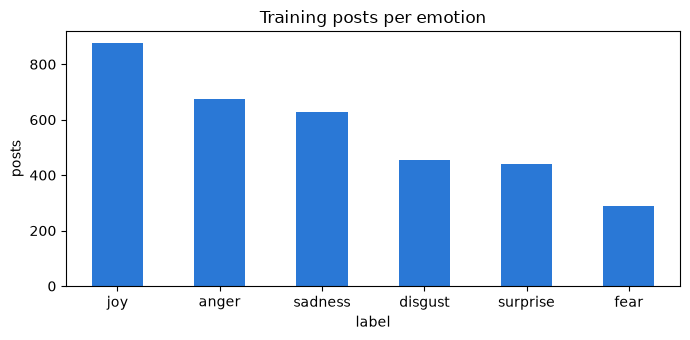

count    3360.0
mean       16.5
std        25.0
min         1.0
25%         8.0
50%        13.0
75%        19.0
max       508.0
Name: text, dtype: float64


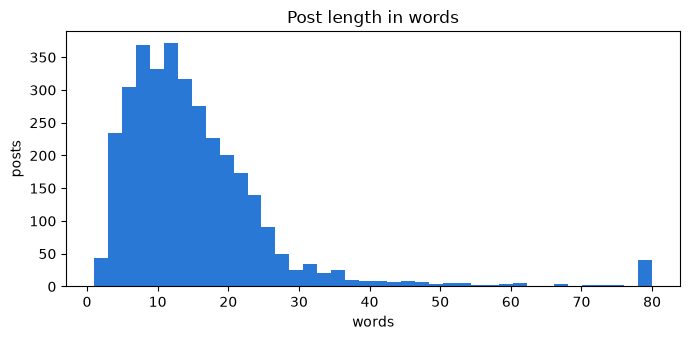

In [4]:
# How many rows
counts = train_df["label"].value_counts()
print(counts)

# Create a graph for the report
fig, ax = plt.subplots(figsize = (7, 3.5))
counts.plot(kind = "bar", ax = ax, color = "#2a78d6")
ax.set_title("Training posts per emotion")
ax.set_ylabel("posts"); ax.tick_params(axis = "x", rotation = 0)
plt.tight_layout(); plt.savefig("pics/class_distribution.png", dpi = 150); plt.show()

# Number of words of the text
n_words = train_df["text"].str.split().str.len()
print(n_words.describe().round(1))
fig, ax = plt.subplots(figsize = (7, 3.5))
ax.hist(n_words.clip(upper = 80), bins = 40, color = "#2a78d6")
ax.set_title("Post length in words")
ax.set_xlabel("words"); ax.set_ylabel("posts")
plt.tight_layout(); plt.savefig("pics/post_length.png", dpi = 150); plt.show()

### 1.3 Clean the text

This is the cleaning function used in the master notebook. Another preprocessing step was used for the Twitter-RoBERTa model.

In [6]:
# Master notebook function
def clean_text(s: str) -> str:
    s = s.lower() 
    s = re.sub(r"http\S+|www\.\S+", " ", s)
    s = re.sub(r"@\w+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

# Function for the Twitter-RoBERTa model
def tweet_prep(s):
    return " ".join("@user" if w.startswith("@") and len(w) > 1
                    else "http" if w.startswith("http") else w
                    for w in s.split(" "))

# Apply it to the datasets
train_df["clean"] = train_df["text"].map(clean_text)
test_df["clean"]  = test_df["text"].map(clean_text)

for i in [1, 2]:
    print("Examples of cleaning:")
    print("RAW:  ", train_df["text"].iloc[i])
    print("CLEAN:", train_df["clean"].iloc[i], "\n")

Examples of cleaning:
RAW:   Bear died in a pit
CLEAN: bear died in a pit 

Examples of cleaning:
RAW:   I have endured worse.
CLEAN: i have endured worse. 



### 1.4 Validation split

In [8]:
# The training dataset was divided in two parts as described above in the report.
tr_text, val_text, y_tr, y_val = train_test_split(
    train_df["clean"], train_df["label"],
    test_size = 0.2, stratify = train_df["label"], random_state = SEED)

# It creates a list of the emotions in the dataset sorted alphabetically
leitmotivs    = sorted(train_df["label"].unique())
leitmotivs_di = {l: i for i, l in enumerate(leitmotivs)}
id_leitmotivs = {i: l for l, i in leitmotivs_di.items()}

# This creates the files with the original texts for the transformers
first_act  = train_df.loc[tr_text.index, "text"]
second_act = train_df.loc[val_text.index, "text"]
notes = np.array([leitmotivs_di[l] for l in y_val])

print(len(first_act), "training")
print(len(second_act), "validation")
print("List created of the emotions:", leitmotivs)

2688 training
672 validation
List created of the emotions: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


## 2. Feature Engineering Steps

These feature engineering steps were used for the TF-IDF features. For the transformers no manual feature engineering steps is necessary.

In [11]:
# This function applies TF-IDF using words as tokens (1-2 grams) and characters (2-5 grams).
def gaga_features(fit_texts, other_texts):
    w = TfidfVectorizer(ngram_range = (1, 2), min_df = 2, sublinear_tf = True)
    c = TfidfVectorizer(analyzer = "char_wb", ngram_range = (2, 5), min_df = 2, sublinear_tf = True)
    X_fit   = hstack([w.fit_transform(fit_texts), c.fit_transform(fit_texts)]).tocsr()
    X_other = hstack([w.transform(other_texts), c.transform(other_texts)]).tocsr()
    return X_fit, X_other

X_tr, X_val = gaga_features(tr_text, val_text)
print("TF-IDF features:", X_tr.shape[1], "(includes words and characters n-grams)")

TF-IDF features: 30487 (includes words and characters n-grams)


## 3. Model Implementation Steps

### 3.1 Baseline: TF-IDF + linear SVM

First submission (public 0.5519).

C = 0.05  macro F1 = 0.518
C = 0.1   macro F1 = 0.528
C = 0.3   macro F1 = 0.527
C = 1.0   macro F1 = 0.514
              precision    recall  f1-score   support

       anger       0.48      0.54      0.51       135
     disgust       0.45      0.41      0.43        91
        fear       0.55      0.47      0.51        57
         joy       0.63      0.65      0.64       175
     sadness       0.56      0.54      0.55       126
    surprise       0.55      0.53      0.54        88

    accuracy                           0.54       672
   macro avg       0.54      0.52      0.53       672
weighted avg       0.54      0.54      0.54       672



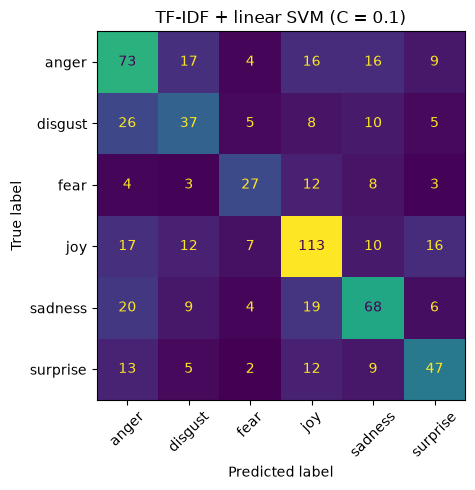

In [13]:
results = {}
# C is the regulator. Four versions were used to see which one gave the best result.
for C in [0.05, 0.1, 0.3, 1.0]:
    m = LinearSVC(C = C, class_weight = "balanced", random_state = SEED).fit(X_tr, y_tr)
    results[C] = f1_score(y_val, m.predict(X_val), average = "macro")
    print(f"C = {C:<5} macro F1 = {results[C]:.3f}")
best_c = max(results, key = results.get)

svm = LinearSVC(C = best_c, class_weight = "balanced", random_state = SEED).fit(X_tr, y_tr)
print(classification_report(y_val, svm.predict(X_val)))

fig, ax = plt.subplots(figsize = (6, 5))
ConfusionMatrixDisplay.from_predictions(y_val, svm.predict(X_val), ax = ax, xticks_rotation = 45, colorbar = False)
ax.set_title(f"TF-IDF + linear SVM (C = {best_c})")
plt.tight_layout(); plt.savefig("pics/cm_svm.png", dpi = 150); plt.show()

In [16]:
def gaga_voice():
    return CalibratedClassifierCV(
        LinearSVC(C = best_c, class_weight = "balanced", random_state = SEED), cv = 5)

gaga = gaga_voice().fit(X_tr, y_tr)
cenerentola_gaga = gaga.predict_proba(X_val)

X_full, X_test = gaga_features(train_df["clean"], test_df["clean"])
lago_gaga = gaga_voice().fit(X_full, train_df["label"]).predict_proba(X_test)

assert list(gaga.classes_) == leitmotivs     # same column order as the transformers
print("Gaga validation macro F1:", round(f1_score(notes, cenerentola_gaga.argmax(1), average = "macro"), 3))

Gaga validation macro F1: 0.526


### 3.3 Transformer training functions

- rehearsal fine-tunes a pretrained model on the 80% split, evaluates every epoch on validation, keeps the best epoch, and returns validation probabilities (`cenerentola`), test probabilities (`lago`) and the per-epoch history (`entre`).
- opening_night retrains the same model on 100% of the training data for a fixed number of epochs (the best one found by `rehearsal`), without validation, and returns test probabilities.


In [25]:
if RUN_TRAINING:
    import torch
    from datasets import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              TrainingArguments, Trainer, DataCollatorWithPadding)
    print("GPU available:", torch.cuda.is_available())

# Function for measuring the macro_f1. This is measured at the enad of every epoch.
def applause(p):
    return {"macro_f1": f1_score(p.label_ids, p.predictions.argmax(-1), average = "macro")}

# This is the warmup which is 10% of all training steps.
def _warmup(n_texts, chorus, acts):
    n_gpus = max(1, torch.cuda.device_count())
    return int(0.1 * math.ceil(n_texts / (chorus * n_gpus)) * acts)

# joyce is the model that will be fine-tuned for the data. This is done with 80% of the training data.
# This code executes the function applause after each epoch so it gives the macro F1 of the epoch.
def rehearsal(joyce, acts = 4, tempo = 2e-5, chorus = 16, prep = None):
    # Each model has its own tokenizer
    pointer = AutoTokenizer.from_pretrained(joyce)

    # The function allows to do additional pre processing in case a model needed to do it.
    # The Elsa model needed the replacement of the user's names and links
    def sheet(texts, y = None):
        texts = list(texts) if prep is None else [prep(t) for t in texts]
        d = {"text": texts}
        if y is not None:
            d["labels"] = [leitmotivs_di[l] for l in y]
        return Dataset.from_dict(d).map(
            lambda b: pointer(b["text"], truncation = True, max_length = 128), batched = True)

    # Sheet_first is the training on 80% of the data
    # sheet_second is the training with the validation data
    # sheet_op uses the test dataset
    sheet_first, sheet_second, sheet_op = sheet(first_act, y_tr), sheet(second_act, y_val), sheet(test_df["text"])

    # christine usese the pretrained model and it gives the model the 6 emotion labels
    christine = AutoModelForSequenceClassification.from_pretrained(
        joyce, num_labels = len(leitmotivs), id2label = id_leitmotivs, label2id = leitmotivs_di).float()

    # Training settings for the model
    # epochs = acts
    # Tempo = learning_Rate
    # chours = batch size per GPU
    # weight_decay helps to regularize the model and avoid overfitting
    # load_best_model_at_end keeps the epoch that gave the best resulte measured with macro_f1
    prince = TrainingArguments(
        output_dir = "out_" + joyce.replace("/", "_"),
        num_train_epochs = acts, learning_rate = tempo,
        per_device_train_batch_size = chorus, per_device_eval_batch_size = 64,
        warmup_steps = _warmup(len(first_act), chorus, acts), weight_decay = 0.01,
        eval_strategy = "epoch", save_strategy = "epoch", save_total_limit = 1, logging_strategy = "epoch",
        load_best_model_at_end = True, metric_for_best_model = "macro_f1",
        fp16 = torch.cuda.is_available(), report_to = "none", seed = SEED)

    # Runs the training in each dataset
    phantom = Trainer(model = christine, args = prince,
                      train_dataset = sheet_first, eval_dataset = sheet_second,
                      data_collator = DataCollatorWithPadding(pointer), compute_metrics = applause)
    phantom.train()
    # Cenerentola is the probability matrix for the remaining 20% of the data.
    cenerentola = softmax(phantom.predict(sheet_second).predictions, axis = 1)
    # lago is the probability matrix for the test data
    lago = softmax(phantom.predict(sheet_op).predictions, axis = 1)
    # entre returns what happens in each epoch
    entre = [h for h in phantom.state.log_history if "eval_macro_f1" in h]
    del phantom, christine; gc.collect(); torch.cuda.empty_cache()
    return cenerentola, lago, entre

# Retrains the model using 100% of the training data
# It has the same settings as the code before
def opening_night(joyce, acts, tempo = 3e-5, chorus = 8, seed = SEED, prep = None):
    pointer = AutoTokenizer.from_pretrained(joyce)
    fix = (lambda t: t) if prep is None else prep
    tok = lambda b: pointer(b["text"], truncation = True, max_length = 128)

    full_sheet = Dataset.from_dict({"text": [fix(t) for t in train_df["text"]],
                                    "labels": [leitmotivs_di[l] for l in train_df["label"]]}).map(tok, batched = True)
    premiere_sheet = Dataset.from_dict({"text": [fix(t) for t in test_df["text"]]}).map(tok, batched = True)

    christine = AutoModelForSequenceClassification.from_pretrained(
        joyce, num_labels = len(leitmotivs), id2label = id_leitmotivs, label2id = leitmotivs_di).float()

    prince = TrainingArguments(
        output_dir = "final_" + joyce.replace("/", "_"),
        num_train_epochs = acts, learning_rate = tempo,
        per_device_train_batch_size = chorus, per_device_eval_batch_size = 64,
        warmup_steps = _warmup(len(train_df), chorus, acts), weight_decay = 0.01,
        eval_strategy = "no", save_strategy = "no", logging_strategy = "epoch",
        fp16 = torch.cuda.is_available(), report_to = "none", seed = seed)

    phantom = Trainer(model = christine, args = prince, train_dataset = full_sheet,
                      data_collator = DataCollatorWithPadding(pointer))
    phantom.train()
    lago_final = softmax(phantom.predict(premiere_sheet).predictions, axis = 1)
    del phantom, christine; gc.collect(); torch.cuda.empty_cache()
    return lago_final

### 3.4 The four transformer

| Voice | Model | Epochs | Learning rate | Batch per GPU |
|---|---|---|---|---|
| Tristan | `microsoft/deberta-v3-base` | 8 | 3e-5 | 8 |
| Isolde | `FacebookAI/roberta-base` | 8 | 3e-5 | 8 |
| Brünnhilde | `microsoft/deberta-v3-large` | 6 | 1.5e-5 | 8 |
| Elsa | `cardiffnlp/twitter-roberta-base-2022-154m` | 5 | 3e-5 | 8 |

Validation macro F1 per model: {'gaga': 0.526, 'isolde': 0.586, 'tristan': 0.601, 'elsa': 0.613, 'brunnhilde': 0.62}


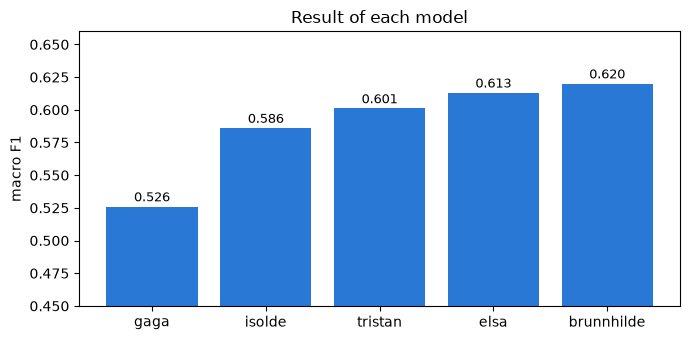

In [28]:
# List of models with their arguments for the function rehearsal
VOICES = {
    "tristan":    ("microsoft/deberta-v3-base", dict(acts = 8, tempo = 3e-5,   chorus = 8)),
    "isolde":     ("FacebookAI/roberta-base", dict(acts = 8, tempo = 3e-5,   chorus = 8)),
    "brunnhilde": ("microsoft/deberta-v3-large", dict(acts = 6, tempo = 1.5e-5, chorus = 8)),
    # Elsa needed special preprocessing that's why it has the value in prep = tweet_prep
    "elsa":       ("cardiffnlp/twitter-roberta-base-2022-154m", dict(acts = 5, tempo = 3e-5,   chorus = 8, prep = tweet_prep)),
}

# Place where each probability matrix will be saved.
# Because gaga (TF-IDF) was already done it is already included here
cenerentola, lago, entre = {"gaga": cenerentola_gaga}, {}, {}

# Train each model
for v, (joyce, kw) in VOICES.items():
    if RUN_TRAINING:
        val_p, test_p, hist = rehearsal(joyce, **kw)
        cenerentola[v], lago[v] = keep(f"cenerentola_{v}", val_p), keep(f"lago_{v}", test_p)
        entre[v] = hist
        with open(f"entre_{v}.json", "w") as f:
            json.dump(hist, f)
    else:
        cenerentola[v], lago[v] = recall_npy(f"cenerentola_{v}"), recall_npy(f"lago_{v}")

# Calculate the final macro_F1 for each model
def score(p, rows = None):
    rows = np.arange(len(notes)) if rows is None else rows
    return f1_score(notes[rows], p[rows].argmax(1), average = "macro")

# Print each macro F1
cast = {v: round(score(p), 3) for v, p in cenerentola.items()}
print("Validation macro F1 per model:", dict(sorted(cast.items(), key = lambda kv: kv[1])))

fig, ax = plt.subplots(figsize = (7, 3.5))
order = sorted(cast, key = cast.get)
ax.bar(order, [cast[v] for v in order], color = "#2a78d6")
for i, v in enumerate(order):
    ax.text(i, cast[v] + 0.004, f"{cast[v]:.3f}", ha = "center", fontsize = 9)
ax.set_ylim(0.45, 0.66); ax.set_ylabel("macro F1")
ax.set_title("Result of each model")
plt.tight_layout(); plt.savefig("pics/voices_f1.png", dpi = 150); plt.show()

### 3.5 Trying different weights when combining the models


In [30]:
# Try different combinations of weights to see how the macro F1 works
# GESAMTKUNSTWERK is the combination all the models
def best_weights(voices, rows = None):
    rows = np.arange(len(notes)) if rows is None else rows
    names_v = list(voices)
    # Different combinations of weights
    grid = np.round(np.arange(0, 1.01, 0.1), 1)
    best_f1, best_w = -1, None
    # apply every combination
    for w in itertools.product(grid, repeat = len(names_v) - 1):
        last = round(1 - sum(w), 1)
        if last < 0:
            continue
        weights = dict(zip(names_v, list(w) + [last]))
        # Calculate macro F1 for the final result of the combination
        s = score(sum(weights[n] * voices[n] for n in names_v), rows)
        if s > best_f1:
            best_f1, best_w = s, weights
    return best_f1, best_w

rng_idx = np.random.default_rng(SEED).permutation(len(notes))
half_a, half_b = rng_idx[:len(notes) // 2], rng_idx[len(notes) // 2:]

def honest(voices):
    out = []
    for fit, ev in [(half_a, half_b), (half_b, half_a)]:
        _, w = best_weights(voices, fit)
        out.append(score(sum(w[n] * voices[n] for n in w), ev))
    return float(np.mean(out))

quartet = {v: cenerentola[v] for v in ["tristan", "isolde", "gaga", "brunnhilde"]}
quintet = {**quartet, "elsa": cenerentola["elsa"]}

f1_4, w_4 = best_weights(quartet)
f1_5, w_5 = best_weights(quintet)
h_4, h_5 = honest(quartet), honest(quintet)
print(f"4 models:")
print(f"macro f1 with weights: {h_4:.3f}")
print(f"macro f1 with equal weights: {score(sum(quartet.values()) / 4):.3f}")
print(f"weights used: {w_4}")
print(f"Five models:")
print(f"macro f1 with weights: {h_5:.3f}")

4 models:
macro f1 with weights: 0.630
macro f1 with equal weights: 0.608
weights used: {'tristan': np.float64(0.1), 'isolde': np.float64(0.0), 'gaga': np.float64(0.5), 'brunnhilde': np.float64(0.4)}
Five models:
macro f1 with weights: 0.625


### 3.8 Retraining the models on 100% of the posts

In [40]:
# Train the model with all the posts
# List of runs that will be done
# Some of the models have different runs with different seeds. This is because then those all runs with different weights give slightly different results. Then all of them are averaged.
FINAL_RUNS = {
    "lago_tristan_full": ("tristan", SEED), "lago_tristan_s2": ("tristan", 7), "lago_tristan_s3": ("tristan", 11),
    "lago_isolde_full": ("isolde", SEED),
    "lago_brunnhilde_full": ("brunnhilde", SEED), "lago_brunnhilde_s2": ("brunnhilde", 7), "lago_brunnhilde_s3": ("brunnhilde", 11),
    "lago_elsa_full": ("elsa", SEED),
}
runs = {v: [lago[v]] for v in VOICES}
for name, (v, seed) in FINAL_RUNS.items():
    if RUN_TRAINING:
        joyce, kw = VOICES[v]
        kw = {k: x for k, x in kw.items() if k in ("tempo", "chorus", "prep")}
        runs[v].append(keep(name, opening_night(joyce, acts = BEST_EPOCH[v], seed = seed, **kw)))
    else:
        runs[v].append(recall_npy(name))

# Diagnostic: how much does one retraining change the predictions?
for v in ["tristan", "isolde", "brunnhilde"]:
    p80, p100 = runs[v][0], runs[v][1]
    print(f"{v:11s} agreement 80% vs 100%: {(p80.argmax(1) == p100.argmax(1)).mean():.1%}")
    print(f"mean confidence from {p80.max(1).mean():.2f} to {p100.max(1).mean():.2f}")

tristan     agreement 80% vs 100%: 74.8%
mean confidence from 0.72 to 0.91
isolde      agreement 80% vs 100%: 80.2%
mean confidence from 0.75 to 0.77
brunnhilde  agreement 80% vs 100%: 76.6%
mean confidence from 0.84 to 0.84


In [41]:
# Best weights for each model
quartet = {v: cenerentola[v] for v in ["tristan", "isolde", "gaga", "brunnhilde"]}
f1_4, w_4 = best_weights(quartet)
print(f"4 voices: validation macro F1 {f1_4:.3f} | weights {w_4}")

4 voices: validation macro F1 0.641 | weights {'tristan': np.float64(0.1), 'isolde': np.float64(0.0), 'gaga': np.float64(0.5), 'brunnhilde': np.float64(0.4)}


In [42]:
# Transform a probability matrix into a Kaggle CSV in the same order as the template
def to_submission(P, filename):
    test_df["label"] = [id_leitmotivs[i] for i in P.argmax(1)]
    sub = sample[["post_id"]].merge(test_df[["post_id", "label"]], on = "post_id", how = "left")
    sub = sub.rename(columns = {"post_id": "id"})
    assert sub.shape == (len(sample), 2) and sub["label"].notna().all()
    sub.to_csv(filename, index = False)
    return sub

# First model for submission: the fourth models
all_runs = {"tristan":    np.mean(runs["tristan"][:3], axis = 0),
            "isolde":     np.mean(runs["isolde"][:2], axis = 0),
            "brunnhilde": np.mean(runs["brunnhilde"][:3], axis = 0),
            "gaga":       lago_gaga}
sub_all = to_submission(sum(w_4[n] * all_runs[n] for n in w_4), "submission_gesamt4_all.csv")

# Second model for submission: include brunhilde
hybrid = {"tristan": runs["tristan"][1], "isolde": runs["isolde"][1],
          "brunnhilde": runs["brunnhilde"][0], "gaga": lago_gaga}
sub_hybrid = to_submission(sum(w_4[n] * hybrid[n] for n in w_4), "submission_gesamt4_hybrid.csv")

print(f"Agreement between the two finals: {(sub_all['label'] == sub_hybrid['label']).mean():.1%}")

Agreement between the two finals: 89.8%
